# 05 uv Coverage

**Series:** Physics of the CHARA Array (Mount Wilson Observatory)
**Topic T5:** which parts of the uv plane CHARA measures, and how that decides what it can see.

Notebook 03 showed that each baseline measures one point of the source's Fourier transform, the uv plane. To learn a source's shape you need many points. CHARA gets them two ways:

1. **Many telescope pairs.** Six telescopes give 15 baselines.
2. **Earth's rotation.** As the star crosses the sky, each baseline is seen from a changing angle. Its uv point slides along a curve. This is called **Earth-rotation synthesis**.

The pattern of measured points is the **uv coverage**. It plays the same role as a mirror's shape in notebook 01: it sets the interferometer's effective point spread function.

In [1]:
%matplotlib inline
import itertools

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from astropy.io import fits
from ipywidgets import interact, FloatSlider, Checkbox, Dropdown

RAD_TO_MAS = 180 / np.pi * 3600 * 1000  # radians -> milliarcseconds
MAS_TO_RAD = 1 / RAD_TO_MAS

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
SLIDER_STYLE = {"handle_color": BLUE}  # visible knob on white backgrounds
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "lines.linewidth": 2,
})

# Telescope positions in metres (east, north, up) relative to S1,
# from ten Brummelaar et al. (2005, ApJ 628, 453).
STATIONS = {
    "S1": (0.000, 0.000, 0.000),
    "S2": (-5.748, 33.581, 0.637),
    "E1": (125.333, 305.928, -5.919),
    "E2": (70.389, 269.715, -2.803),
    "W1": (-175.068, 216.327, -10.798),
    "W2": (-69.085, 199.342, 0.471),
}
PAIRS = list(itertools.combinations(STATIONS, 2))
LATITUDE = np.radians(34.2244)  # Mount Wilson
MIN_ALTITUDE_DEG = 30           # simple observing limit used in this notebook
WAVELENGTH = 1.65e-6            # H band

## 1. The array layout

CHARA's six 1 m telescopes are spread over the Mount Wilson summit in a Y shape. Two sit on each arm: south (S), east (E) and west (W). Light from each travels through pipes to a central lab where the delay lines and beam combiners are.

Six telescopes make $6 \times 5 / 2 = 15$ pairs. Each pair is one baseline, with its own length **and direction**.

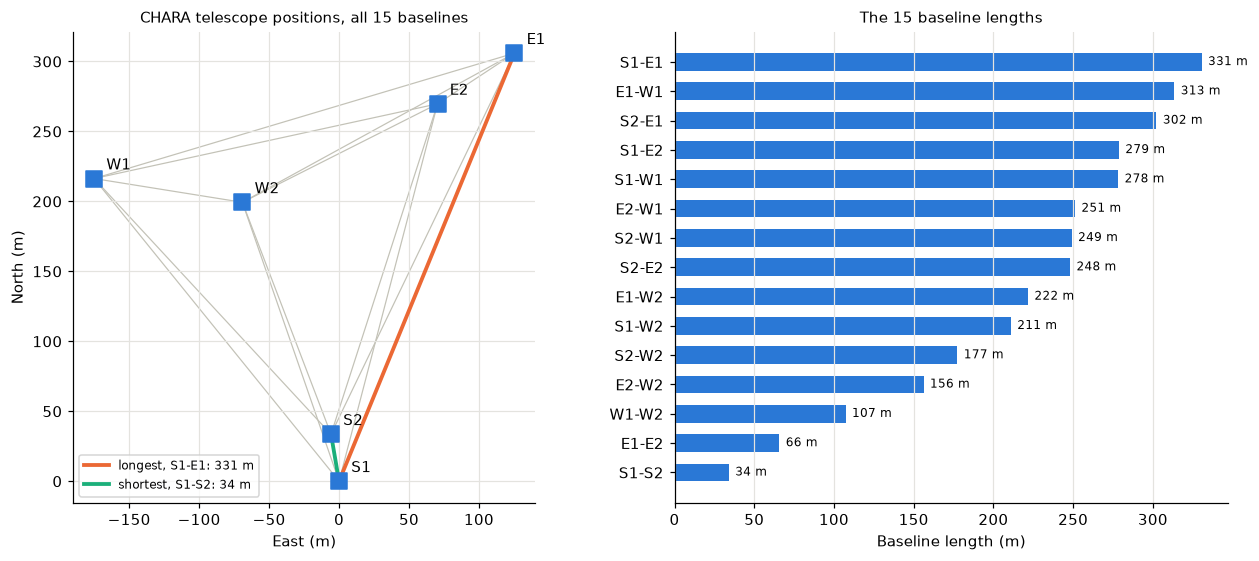

In [2]:
def baseline_vector(t1, t2):
    return np.subtract(STATIONS[t2], STATIONS[t1])


lengths = {f"{a}-{b}": np.hypot(*baseline_vector(a, b)[:2]) for a, b in PAIRS}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
for a, b in PAIRS:
    (e1, n1, _), (e2, n2, _) = STATIONS[a], STATIONS[b]
    ax1.plot([e1, e2], [n1, n2], color="#c3c2b7", lw=0.8, zorder=1)
for name, (e, n, _) in STATIONS.items():
    ax1.scatter(e, n, s=120, marker="s", color=BLUE, zorder=3)
    ax1.annotate(name, (e, n), xytext=(8, 6), textcoords="offset points", fontsize=10)
for (a, b), colour, label in [(("S1", "E1"), ORANGE, "longest, S1-E1"),
                              (("S1", "S2"), AQUA, "shortest, S1-S2")]:
    (e1, n1, _), (e2, n2, _) = STATIONS[a], STATIONS[b]
    ax1.plot([e1, e2], [n1, n2], color=colour, lw=2.5, zorder=2,
             label=f"{label}: {lengths[a + '-' + b]:.0f} m")
ax1.set_aspect("equal")
ax1.set_xlabel("East (m)")
ax1.set_ylabel("North (m)")
ax1.set_title("CHARA telescope positions, all 15 baselines", fontsize=10)
ax1.legend(fontsize=8, loc="lower left")

ordered = sorted(lengths.items(), key=lambda item: item[1])
ax2.barh([name for name, _ in ordered], [length for _, length in ordered], color=BLUE, height=0.6)
for i, (_, length) in enumerate(ordered):
    ax2.text(length + 4, i, f"{length:.0f} m", va="center", fontsize=8)
ax2.set_xlabel("Baseline length (m)")
ax2.set_title("The 15 baseline lengths", fontsize=10)
ax2.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 2. The baseline as seen from the star

What matters for interferometry is not the baseline on the ground but the baseline **as seen from the star**. Picture looking back at Mount Wilson from the star. The two telescopes appear closer together if the star is low on the sky, because the baseline is foreshortened. The direction also changes.

That projected baseline, split into its east-west and north-south parts, is exactly the $(u, v)$ point from notebook 03, here measured in metres. The conversion uses the star's **declination** (how far north it is on the sky) and its **hour angle** (how many hours past its highest point it is). Each point has a mirror point at $(-u, -v)$, which carries no new information.

The sliders choose the telescopes and when the star is observed.

In [3]:
def to_equatorial(enu):
    # Local east/north/up -> equatorial X (toward hour angle 0), Y (east), Z (north pole)
    e, n, up = enu
    x = -np.sin(LATITUDE) * n + np.cos(LATITUDE) * up
    z = np.cos(LATITUDE) * n + np.sin(LATITUDE) * up
    return x, e, z


def project(enu, hour_angle, dec):
    # Projected baseline (u east, v north, w toward the star) in metres
    x, y, z = to_equatorial(enu)
    u = np.sin(hour_angle) * x + np.cos(hour_angle) * y
    v = (-np.sin(dec) * np.cos(hour_angle) * x + np.sin(dec) * np.sin(hour_angle) * y
         + np.cos(dec) * z)
    w = (np.cos(dec) * np.cos(hour_angle) * x - np.cos(dec) * np.sin(hour_angle) * y
         + np.sin(dec) * z)
    return u, v, w


def altitude_deg(hour_angle, dec):
    s = (np.sin(LATITUDE) * np.sin(dec)
         + np.cos(LATITUDE) * np.cos(dec) * np.cos(hour_angle))
    return np.degrees(np.arcsin(s))


telescope_boxes = {name: Checkbox(value=True, description=name, indent=False) for name in STATIONS}


@interact(
    dec_deg=FloatSlider(value=34, min=-25, max=85, step=1, description="dec (°)",
                        continuous_update=False, style=SLIDER_STYLE),
    hour_angle_h=FloatSlider(value=0, min=-5, max=5, step=0.25, description="HA (h)",
                             continuous_update=False, style=SLIDER_STYLE),
    **telescope_boxes,
)
def show_snapshot(dec_deg, hour_angle_h, **selected):
    chosen = [name for name, on in selected.items() if on]
    pairs = list(itertools.combinations(chosen, 2))
    dec, ha = np.radians(dec_deg), np.radians(15 * hour_angle_h)
    alt = altitude_deg(ha, dec)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2))
    for a, b in pairs:
        (e1, n1, _), (e2, n2, _) = STATIONS[a], STATIONS[b]
        ax1.plot([e1, e2], [n1, n2], color=BLUE, lw=1, alpha=0.6)
    for name, (e, n, _) in STATIONS.items():
        on = name in chosen
        ax1.scatter(e, n, s=110, marker="s", color=BLUE if on else "#e4e3df", zorder=3)
        ax1.annotate(name, (e, n), xytext=(8, 6), textcoords="offset points", fontsize=9)
    ax1.set_aspect("equal")
    ax1.set_xlabel("East (m)")
    ax1.set_ylabel("North (m)")
    ax1.set_title(f"{len(chosen)} telescopes, {len(pairs)} baselines on the ground", fontsize=10)

    for a, b in pairs:
        u, v, _ = project(baseline_vector(a, b), ha, dec)
        ax2.scatter([u, -u], [v, -v], s=40, color=[BLUE, ORANGE])
    ax2.scatter([], [], color=BLUE, label="(u, v)")
    ax2.scatter([], [], color=ORANGE, label="mirror (−u, −v)")
    ax2.set_aspect("equal")
    ax2.set_xlim(-340, 340)
    ax2.set_ylim(-340, 340)
    ax2.set_xlabel("u, east-west (m)")
    ax2.set_ylabel("v, north-south (m)")
    status = "" if alt >= MIN_ALTITUDE_DEG else "  (below 30°, not observable)"
    ax2.set_title(f"uv snapshot, star altitude {alt:.0f}°{status}", fontsize=10)
    ax2.legend(fontsize=8, loc="upper right")
    plt.tight_layout()
    plt.show()

interactive(children=(FloatSlider(value=34.0, continuous_update=False, description='dec (°)', max=85.0, min=-2…

**Try this:**

- Untick telescopes. Two telescopes give one baseline: two points. Six give 30.
- Set declination 34° (the star passes straight overhead) and HA 0. The uv points match the ground layout, rotated 180° for the mirror points.
- Move the hour angle. The pattern rotates and shrinks as the star moves away from overhead.

## 3. Earth-rotation synthesis

Now let the star cross the sky through a night. Every baseline's uv point traces a curve, part of an **ellipse**. A few hours of observing turns 30 points into 30 arcs.

- The ellipse's east-west size is the baseline's full length.
- Its north-south size is squeezed by the sine of the declination. Stars far north (high declination) give round ellipses. Stars near the celestial equator give flat ones, with little north-south coverage.

The tracks stop where the star drops below 30° altitude. Low on the sky the light passes through too much atmosphere. Real CHARA observations also have limits from the delay lines' range, which this notebook ignores.

In [4]:
@interact(
    dec_deg=FloatSlider(value=40, min=-25, max=85, step=1, description="dec (°)",
                        continuous_update=False, style=SLIDER_STYLE),
    hours=FloatSlider(value=6, min=0, max=12, step=0.5, description="hours",
                      continuous_update=False, style=SLIDER_STYLE),
)
def show_tracks(dec_deg, hours):
    dec = np.radians(dec_deg)
    ha_h = np.linspace(-hours / 2, hours / 2, 400)
    ha = np.radians(15 * ha_h)
    alt = altitude_deg(ha, dec)
    up = alt >= MIN_ALTITUDE_DEG

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={"width_ratios": [1.3, 1]})
    for a, b in PAIRS:
        u, v, _ = project(baseline_vector(a, b), ha, dec)
        ax1.plot(np.where(up, u, np.nan), np.where(up, v, np.nan), color=BLUE, lw=1.5)
        ax1.plot(np.where(up, -u, np.nan), np.where(up, -v, np.nan), color=ORANGE, lw=1.5)
    ax1.plot([], [], color=BLUE, label="(u, v)")
    ax1.plot([], [], color=ORANGE, label="mirror")
    ax1.set_aspect("equal")
    ax1.set_xlim(-340, 340)
    ax1.set_ylim(-340, 340)
    ax1.set_xlabel("u, east-west (m)")
    ax1.set_ylabel("v, north-south (m)")
    ax1.set_title(f"All 15 baselines, dec {dec_deg:.0f}°, up to {hours:.1f} h", fontsize=10)
    ax1.legend(fontsize=8, loc="upper right")

    full_ha = np.linspace(-6, 6, 400)
    ax2.plot(full_ha, altitude_deg(np.radians(15 * full_ha), dec), color=GREY, lw=1.5)
    ax2.plot(ha_h[up], alt[up], color=BLUE, lw=3, label="observed")
    ax2.axhline(MIN_ALTITUDE_DEG, color=ORANGE, ls="--", lw=1, label="30° limit")
    ax2.set_ylim(0, 90)
    ax2.set_xlabel("Hour angle (h, 0 = highest point)")
    ax2.set_ylabel("Altitude (°)")
    ax2.set_title("The star's height in the sky", fontsize=10)
    ax2.legend(fontsize=8, loc="lower center")
    plt.tight_layout()
    plt.show()

    print(f"Time above 30° altitude: {np.ptp(ha_h[up]) if up.any() else 0:.1f} h of the {hours:.1f} h requested")

interactive(children=(FloatSlider(value=40.0, continuous_update=False, description='dec (°)', max=85.0, min=-2…

**Try this:**

- Set declination 0° (a star on the celestial equator). The tracks collapse into nearly straight east-west lines. Detail north-south is poorly measured.
- Set declination 70°. The tracks become rounder ellipses and fill the plane much better.
- Set hours to 0. Only the snapshot dots remain.
- Set declination −20°. The star never climbs far above the horizon from Mount Wilson, so the usable tracks are short.

## 4. Checking against real data

The δ Cep measurements from notebook 04 recorded their $(u, v)$ points. If the telescope positions and the projection above are right, every measured point should sit on the predicted track for δ Cep's declination (+58.4°).

This needs the files downloaded by notebook 04. Run that notebook first if `data/delta_cep/` is empty.

E1-E2: 168 points, largest distance from predicted track 1.8 cm
S1-S2: 11 points, largest distance from predicted track 0.3 cm


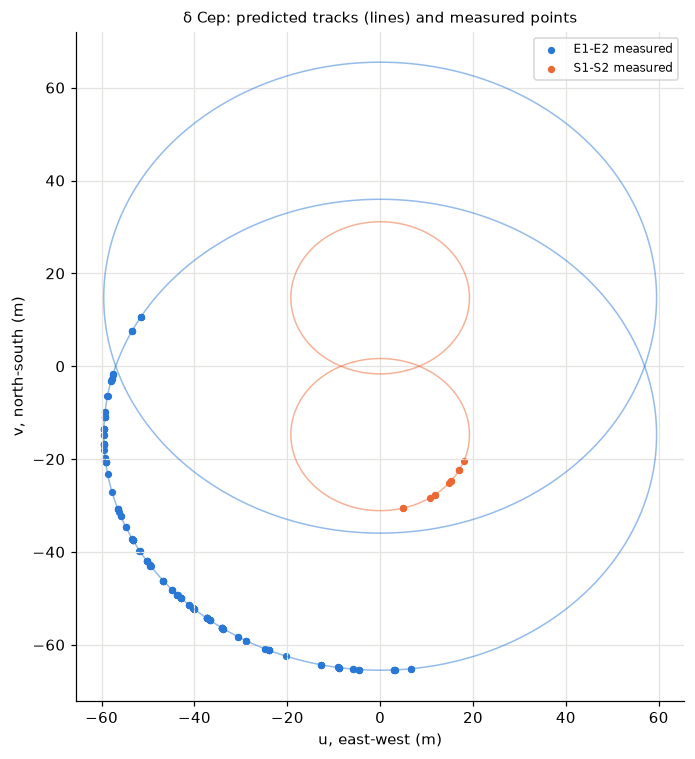

In [5]:
DELTA_CEP_DEC = np.radians(58.41519547)
measured = {}
for path in sorted(Path("data/delta_cep").glob("*.oifits")):
    with fits.open(path) as hdul:
        names = {row["STA_INDEX"]: row["TEL_NAME"].strip() for row in hdul["OI_ARRAY"].data}
        for row in hdul["OI_VIS2"].data:
            pair = tuple(sorted(names[i] for i in row["STA_INDEX"]))
            measured.setdefault(pair, []).append((row["UCOORD"], row["VCOORD"]))

ha = np.radians(np.linspace(-180, 180, 20001))
fig, ax = plt.subplots(figsize=(7, 7))
for (pair, points), colour in zip(sorted(measured.items()), [BLUE, ORANGE]):
    u, v, _ = project(baseline_vector(*pair), ha, DELTA_CEP_DEC)
    ax.plot(u, v, color=colour, lw=1, alpha=0.5)
    ax.plot(-u, -v, color=colour, lw=1, alpha=0.5)
    pts = np.array(points)
    ax.scatter(pts[:, 0], pts[:, 1], s=14, color=colour, label=f"{pair[0]}-{pair[1]} measured")
    # Distance from each measured point to the nearest point on the track or its mirror
    dist = np.min(np.minimum(np.hypot(u[:, None] - pts[:, 0], v[:, None] - pts[:, 1]),
                             np.hypot(u[:, None] + pts[:, 0], v[:, None] + pts[:, 1])), axis=0)
    print(f"{pair[0]}-{pair[1]}: {len(pts)} points, largest distance from predicted track "
          f"{100 * dist.max():.1f} cm")
ax.set_aspect("equal")
ax.set_xlabel("u, east-west (m)")
ax.set_ylabel("v, north-south (m)")
ax.set_title("δ Cep: predicted tracks (lines) and measured points", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Every measured point lies within about 2 cm of its predicted track, on tracks tens of metres across. The geometry in this notebook matches what CHARA recorded.

## 5. Coverage sets the interferometer's point spread function

In notebook 01 the image of a point source was the Fourier transform of the mirror's shape. The same rule holds here, with the uv coverage in place of the mirror. Fourier-transforming the measured points gives the **dirty beam**, the image an interferometer would make of a single point using only those measurements.

Gaps in the coverage show up as **sidelobes**: false ripples around every bright spot. Applying the dirty beam to a real source gives the **dirty image**. Below, the test source is a binary 2 mas across, second star half as bright, at 1.65 µm.

The presets follow how CHARA is used. Some beam combiners take 2 or 3 telescopes at a time. MIRC-X and MYSTIC combine all six.

In [6]:
PRESETS = {
    "2 telescopes: S1, E1": ["S1", "E1"],
    "3 telescopes: S1, E1, W1": ["S1", "E1", "W1"],
    "4 telescopes: S1, E1, W1, W2": ["S1", "E1", "W1", "W2"],
    "6 telescopes (MIRC-X, MYSTIC)": list(STATIONS),
}
FIELD_MAS = 4.0
IMAGE_AXIS = np.linspace(-FIELD_MAS, FIELD_MAS, 161)
STAR_A = (-0.6, -0.6, 1.0)  # x (mas, east), y (mas, north), flux
STAR_B = (1.0, 1.0, 0.5)


def coverage(telescopes, dec, hours):
    ha = np.radians(15 * np.linspace(-hours / 2, hours / 2, max(int(hours * 6), 1)))
    ha = ha[altitude_deg(ha, dec) >= MIN_ALTITUDE_DEG]
    us, vs = [], []
    for a, b in itertools.combinations(telescopes, 2):
        u, v, _ = project(baseline_vector(a, b), ha, dec)
        us.append(u)
        vs.append(v)
    u, v = np.concatenate(us), np.concatenate(vs)
    return np.concatenate([u, -u]), np.concatenate([v, -v])


def dirty_map(u_m, v_m, visibilities):
    # Sum each measured Fourier component back onto the sky.
    # exp(2πi(xu + yv)) splits into an x part and a y part, so one matrix product does it.
    u, v = u_m / WAVELENGTH, v_m / WAVELENGTH
    axis = IMAGE_AXIS * MAS_TO_RAD
    along_x = np.exp(2j * np.pi * np.outer(axis, u))
    along_y = np.exp(2j * np.pi * np.outer(axis, v))
    return np.real((along_y * visibilities) @ along_x.T) / len(u)


def binary_visibility(u_m, v_m):
    u, v = u_m / WAVELENGTH, v_m / WAVELENGTH
    total = 0
    for x, y, flux in (STAR_A, STAR_B):
        total = total + flux * np.exp(-2j * np.pi * (u * x + v * y) * MAS_TO_RAD)
    return total / (STAR_A[2] + STAR_B[2])


@interact(
    preset=Dropdown(options=list(PRESETS), value="6 telescopes (MIRC-X, MYSTIC)",
                    description="Array", layout={"width": "380px"}),
    dec_deg=FloatSlider(value=40, min=-25, max=85, step=1, description="dec (°)",
                        continuous_update=False, style=SLIDER_STYLE),
    hours=FloatSlider(value=6, min=0, max=10, step=0.5, description="hours",
                      continuous_update=False, style=SLIDER_STYLE),
)
def show_dirty_beam(preset, dec_deg, hours):
    u, v = coverage(PRESETS[preset], np.radians(dec_deg), hours)
    if len(u) == 0:
        print("The star never rises above 30° at this declination.")
        return
    beam = dirty_map(u, v, np.ones(len(u)))
    image = dirty_map(u, v, binary_visibility(u, v))

    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6))
    axes[0].scatter(u, v, s=3, color=BLUE)
    axes[0].set_aspect("equal")
    axes[0].set_xlim(-340, 340)
    axes[0].set_ylim(-340, 340)
    axes[0].set_xlabel("u (m)")
    axes[0].set_ylabel("v (m)")
    axes[0].set_title(f"uv coverage, {len(u)} points", fontsize=10)

    extent = [-FIELD_MAS, FIELD_MAS, -FIELD_MAS, FIELD_MAS]
    for ax, data, title in [(axes[1], beam, "Dirty beam (image of a point)"),
                            (axes[2], image, "Dirty image of the binary")]:
        ax.imshow(data, extent=extent, origin="lower", cmap="RdBu_r",
                  vmin=-np.abs(data).max(), vmax=np.abs(data).max())
        ax.set_xlabel("mas (east)")
        ax.set_title(title, fontsize=10)
        ax.grid(False)
    for x, y, _ in (STAR_A, STAR_B):
        axes[2].scatter(x, y, s=120, facecolor="none", edgecolor="black", lw=1.2)
    axes[2].scatter([], [], s=80, facecolor="none", edgecolor="black", label="true star positions")
    axes[2].legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='Array', index=3, layout=Layout(width='380px'), options=('2 telesco…

Red is positive, blue is negative. The dirty beam can go negative because a sum of a few stripe patterns does not have to stay positive.

**Try this:**

- **2 telescopes, 0 hours:** the dirty beam is a set of stripes, the fringe pattern from notebook 01. One baseline measures one stripe direction only.
- **2 telescopes, 6 hours:** Earth's rotation bends the stripes and they fade away from the centre. One baseline is still far from enough to locate the stars.
- **6 telescopes, 6 hours:** a compact central peak with weaker sidelobes. Both stars of the binary appear at their true positions (circles).
- **6 telescopes, declination 0°:** the coverage becomes flat east-west strips with gaps between them. The dirty beam grows strong false copies of the peak to the north and south, and the dirty image shows a false star about as bright as the real faint one.

**Two cautions for later topics:**

- These dirty images assume the visibility phases are known. The atmosphere scrambles them, and recovering phase information is topic T7.
- A dirty image is not the final picture. Image reconstruction fills the gaps between uv points using what we know about real skies, such as brightness never being negative. That is topic T8.

## Summary

| Idea | What it means |
|---|---|
| 15 baselines | 6 telescopes, each pair a baseline with its own length and direction |
| Projected baseline | The baseline as seen from the star. It is the $(u, v)$ point |
| Earth-rotation synthesis | Through the night each uv point traces an ellipse arc |
| Declination | High-declination stars give round tracks. Equatorial stars give flat ones |
| Dirty beam | The Fourier transform of the coverage. The array's point spread function |

1. One baseline at one moment gives one Fourier component and its mirror.
2. More telescopes and more hours fill the uv plane.
3. The coverage pattern decides the effective point spread function, just as the mirror shape did for one telescope.

**Next:** T6, delay lines. How CHARA cancels hundreds of metres of path difference to within microns, and keeps tracking as the star moves.